# FANet from scratch: polyp segmentation with feedback attention
**Chaitanya Shinde · 231070066 · Deep Learning mini-project, B.Tech Computer Engineering Sem VII, 2026–27**

**Paper implemented:** N. K. Tomar et al., *FANet: A Feedback Attention Network for Improved Biomedical Image Segmentation*,
IEEE Transactions on Neural Networks and Learning Systems, vol. 34, no. 11, 2023. DOI 10.1109/TNNLS.2022.3159394.

**Datasets:** Kvasir-SEG (the paper's dataset, 1000 colonoscopy images with polyp masks) and my own leaf-disease dataset,
labelled by hand and augmented in **Roboflow**.

This notebook walks through the whole project with outputs: data → model → feedback memory → training → test-time
iterative refinement → comparison with the paper → ablation → detection view → own Roboflow dataset and transfer.
All model code is in `src/` (written from PyTorch primitives; no pretrained weights, no model libraries); the notebook
imports it so the cells stay short. Long training runs were done with `python -m src.train` (logs in `runs/`); here a
short live demo shows the training loop running, and the final checkpoint is evaluated live.

In [1]:
import os, sys, time, inspect
os.chdir(os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else "."))
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from IPython.display import Image as Show, display
from src.dataset import SegmentationDataset
from src.memory import MaskMemory, otsu_mask
from src.model import FANet, count_parameters
from src.blocks import MixPool
from src.losses import DiceBCELoss
from src.metrics import MetricAverager, BoxAverager, mask_to_boxes
from src.train import run_epoch, pick_device, seed_everything
device = pick_device("auto")
print("repo:", os.getcwd(), "| torch", torch.__version__, "| device", device,
      torch.cuda.get_device_name(0) if device.type == "cuda" else "")

repo: /mnt/Windows_D/College-work/DLproject | torch 2.11.0+cu128 | device cuda NVIDIA GeForce RTX 5050 Laptop GPU


## 1. The problem and the data
Colorectal cancer usually starts as a **polyp**; doctors miss some polyps during colonoscopy. The task is **binary
semantic segmentation**: label every pixel *polyp* (1) or *background* (0). Kvasir-SEG is split 880 / 120 as in the
paper (`python -m src.split --data data/Kvasir-SEG --test 120`). Images are resized to 256×256.

train 880 | test 120 | image tensor (3, 256, 256) | mask (1, 256, 256)
polyp covers 14.2% of a test image on average -> strong class imbalance


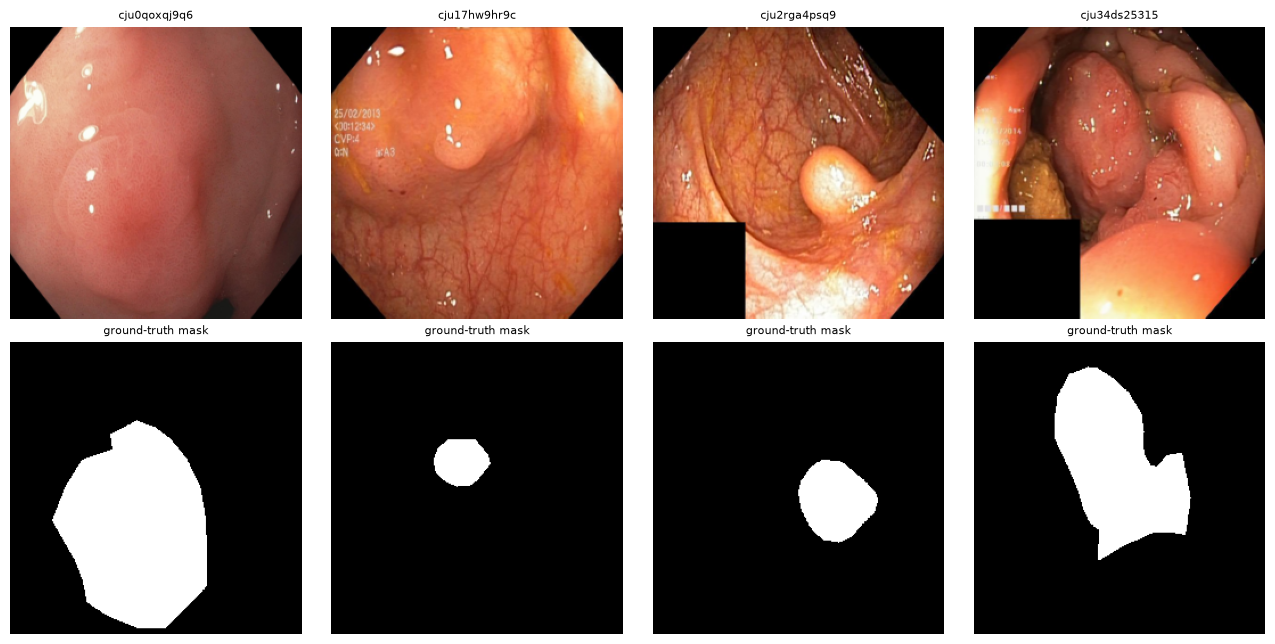

In [2]:
KVASIR = "data/Kvasir-SEG"
test = SegmentationDataset(KVASIR, "test", 256)
n_train = len(open(f"{KVASIR}/train.txt").read().split())
print(f"train {n_train} | test {len(test)} | image tensor {tuple(test[0][0].shape)} | mask {tuple(test[0][1].shape)}")
print(f"polyp covers {test.masks.mean():.1%} of a test image on average -> strong class imbalance")
fig, ax = plt.subplots(2, 4, figsize=(13, 6.5))
for k, i in enumerate([0, 7, 21, 40]):
    ax[0, k].imshow(test.images[i]); ax[0, k].set_title(test.stems[i][:12], fontsize=8)
    ax[1, k].imshow(test.masks[i], cmap="gray"); ax[1, k].set_title("ground-truth mask", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 2. The model: FANet
U-shaped encoder–decoder. Encoder block = ResidualBlock → ResidualBlock → **MixPool** → MaxPool; decoder block =
transposed conv → concat skip → ResidualBlock ×2 → **MixPool**. Every MixPool also receives the **previous mask** of the
image (the feedback). Below: the shapes after each stage, and the parameter count.

In [3]:
net = FANet().to(device).eval()
x = torch.rand(1, 3, 256, 256, device=device); m = torch.zeros(1, 1, 256, 256, device=device)
with torch.no_grad():
    p1, s1 = net.e1(x, m); p2, s2 = net.e2(p1, m); p3, s3 = net.e3(p2, m); p4, s4 = net.e4(p3, m)
    d1 = net.d1(p4, s4, m); d2 = net.d2(d1, s3, m); d3 = net.d3(d2, s2, m); d4 = net.d4(d3, s1, m)
    out = net.head(torch.cat([d4, m], 1))
rows = [(n, tuple(t.shape[1:]), sum(p.numel() for p in getattr(net, b).parameters()))
        for n, t, b in [("E1", p1, "e1"), ("E2", p2, "e2"), ("E3", p3, "e3"), ("E4", p4, "e4"),
                        ("D1", d1, "d1"), ("D2", d2, "d2"), ("D3", d3, "d3"), ("D4", d4, "d4"), ("head", out, "head")]]
display(pd.DataFrame(rows, columns=["stage", "output shape", "parameters"]))
print(f"total trainable parameters: {count_parameters(net):,}")

,stage,output shape,parameters
0,E1,"(32, 128, 128)",48993
1,E2,"(64, 64, 64)",210753
2,E3,"(128, 32, 32)",839297
3,E4,"(256, 16, 16)",3349761
4,D1,"(128, 32, 32)",2461569
5,D2,"(64, 64, 64)",616385
6,D3,"(32, 128, 128)",154593
7,D4,"(16, 256, 256)",38897
8,head,"(1, 256, 256)",18


total trainable parameters: 7,720,266


### MixPool: the feedback-attention block
1. an *fmask* head guesses a mask from the features (thresholded at 0.5);
2. the previous mask is max-pooled to the feature size;
3. attention = fmask **OR** previous mask; features outside it are zeroed (hard attention) → conv;
4. the **unmasked** features go through a second conv, so a wrong mask cannot destroy information;
5. the two halves are concatenated.

In [4]:
print(inspect.getsource(MixPool.forward))

    def forward(self, x, m):
        fmask = (self.fmask(x) > 0.5).float()
        kh, kw = m.shape[2] // x.shape[2], m.shape[3] // x.shape[3]
        m = F.max_pool2d(m, (kh, kw)) if kh > 1 or kw > 1 else m
        attention = torch.logical_or(fmask > 0, m > 0.5).float()
        masked = self.conv1(x * attention)
        plain = self.conv2(x)
        return torch.cat([masked, plain], dim=1)



### The first mask: Otsu's threshold
Before the network has predicted anything, every memory slot holds a classical **Otsu** mask (grey → blur → threshold
that maximises the between-class variance; written from scratch in `src/memory.py`). It picks bright regions, not polyps.

Otsu marks 59.6% of each test image; polyps cover 14.2%


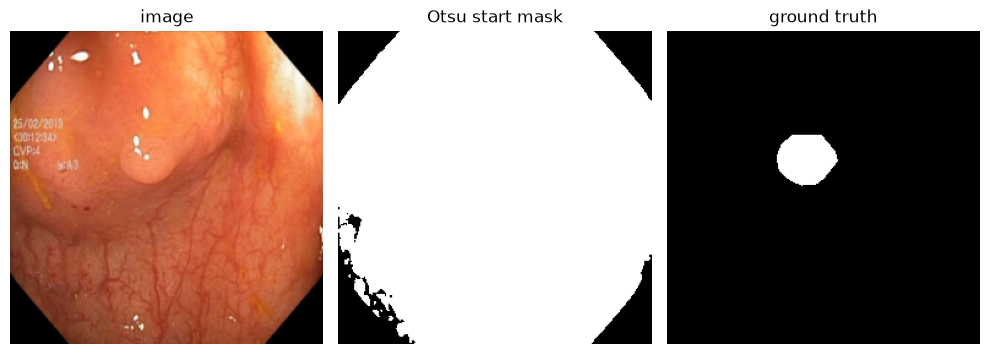

In [5]:
otsu = np.stack([otsu_mask(im) for im in test.images])
print(f"Otsu marks {otsu.mean():.1%} of each test image; polyps cover {test.masks.mean():.1%}")
fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
for a, img, t in zip(ax, [test.images[7], otsu[7], test.masks[7]], ["image", "Otsu start mask", "ground truth"]):
    a.imshow(img, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

## 3. Training with the feedback memory (live demo)
Each epoch: every image is fed with its memory mask; predictions go to a staging copy; if the validation loss improved,
the staged predictions become the memory (and the checkpoint is saved). Loss = 0.5·BCE + 0.5·Dice, Adam (lr 1e-4).
Augmentation as in the official code: rotate ±35°, flips; the memory is **not** moved.

The final model was trained with `python -m src.train --data data/Kvasir-SEG --out runs/kvasir_official --amp`
(147 epochs, best at 107). Here: **3 epochs from scratch**, just to show the loop runs and learns.

In [6]:
from torch.utils.data import DataLoader
seed_everything(0)
train_set = SegmentationDataset(KVASIR, "train", 256)
train_loader = DataLoader(train_set, batch_size=8, shuffle=True, drop_last=True)
test_loader = DataLoader(test, batch_size=8)
demo = FANet().to(device)
opt = torch.optim.Adam(demo.parameters(), lr=1e-4)
train_mem, test_mem = MaskMemory(train_set.images), MaskMemory(test.images)
loss_fn, best = DiceBCELoss(), float("inf")
for epoch in range(1, 4):
    t0 = time.time()
    tl, ts = run_epoch(demo, train_loader, train_mem, loss_fn, device, opt, aug="official")
    vl, vs = run_epoch(demo, test_loader, test_mem, loss_fn, device)
    if vl < best:
        best = vl; train_mem.commit(); test_mem.commit()
    print(f"epoch {epoch} | loss {tl:.3f} / {vl:.3f} | Dice {ts['dice']:.3f} / {vs['dice']:.3f} | {time.time()-t0:.0f}s")

epoch 1 | loss 0.670 / 0.671 | Dice 0.397 / 0.414 | 46s


epoch 2 | loss 0.615 / 0.594 | Dice 0.454 / 0.426 | 61s


epoch 3 | loss 0.587 / 0.576 | Dice 0.473 / 0.454 | 65s


### Learning curves of the real run (`runs/kvasir_official/log.csv`)

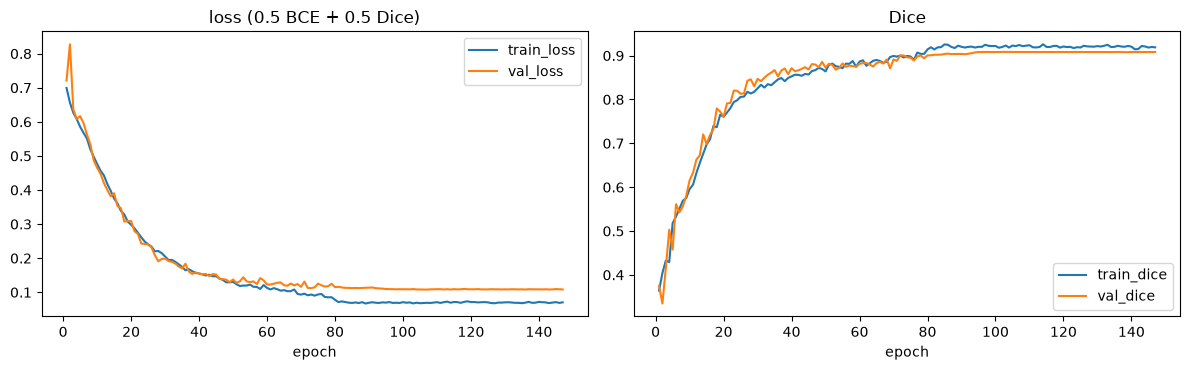

epochs run 147, best epoch 107 (val loss 0.1078)


In [7]:
log = pd.read_csv("runs/kvasir_official/log.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
log.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="loss (0.5 BCE + 0.5 Dice)")
log.plot(x="epoch", y=["train_dice", "val_dice"], ax=ax[1], title="Dice")
plt.tight_layout(); plt.show()
best_row = log.loc[log.val_loss.idxmin()]
print(f"epochs run {len(log)}, best epoch {int(best_row.epoch)} (val loss {best_row.val_loss:.4f})")

## 4. Testing with iterative refinement (live, final checkpoint)
As in the official test script: start each test image's memory from Otsu, predict, feed the prediction back, and repeat
for 10 rounds, recording the metrics after every round. Also run from an **empty** starting mask.

,dice,jaccard,precision,recall,f2
round,,,,,
1,0.6148,0.5115,0.5298,0.9653,0.7291
2,0.7388,0.6557,0.6871,0.9552,0.8107
3,0.7965,0.7258,0.7663,0.9471,0.8430
4,0.8220,0.7568,0.8058,0.9408,0.8561
5,0.8322,0.7685,0.8203,0.9381,0.8617
6,0.8327,0.7689,0.8225,0.9364,0.8616
7,0.8337,0.7700,0.8244,0.9354,0.8622
8,0.8368,0.7729,0.8277,0.9351,0.8647
9,0.8391,0.7754,0.8305,0.9346,0.8663


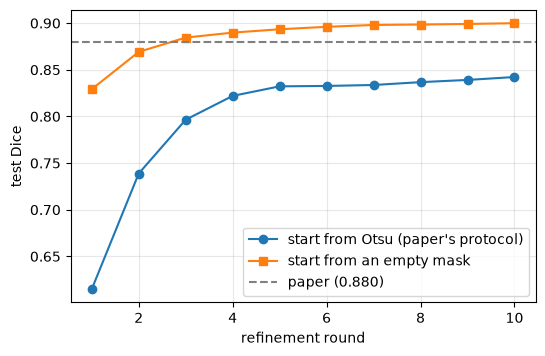

In [8]:
def refine(model, data, start="otsu", rounds=10, batch=8):
    mem = MaskMemory(data.images)
    if start == "zeros":
        mem.masks.zero_(); mem.staged.zero_()
    loader, out = DataLoader(data, batch_size=batch), []
    for r in range(1, rounds + 1):
        scores, boxes = MetricAverager(), BoxAverager()
        for image, target, idx in loader:
            with torch.no_grad():
                probs = torch.sigmoid(model(image.to(device), mem.get(idx, device)))
            mem.write(idx, probs)
            pred = (probs > 0.5).cpu().numpy()
            scores.update(pred, target.numpy()); boxes.update(pred, target.numpy())
        out.append({"round": r, **scores.result(), **boxes.result()})
    return pd.DataFrame(out).set_index("round"), mem

ckpt = torch.load("runs/kvasir_official/best.pt", map_location=device)
model = FANet().to(device); model.load_state_dict(ckpt["model"]); model.eval()
res_otsu, mem_otsu = refine(model, test, "otsu")
res_zero, mem_zero = refine(model, test, "zeros")
display(res_otsu[["dice", "jaccard", "precision", "recall", "f2"]].round(4))
plt.figure(figsize=(6, 3.8))
plt.plot(res_otsu.index, res_otsu.dice, "o-", label="start from Otsu (paper's protocol)")
plt.plot(res_zero.index, res_zero.dice, "s-", label="start from an empty mask")
plt.axhline(0.8803, ls="--", c="gray", label="paper (0.880)")
plt.xlabel("refinement round"); plt.ylabel("test Dice"); plt.legend(); plt.grid(alpha=.3); plt.show()

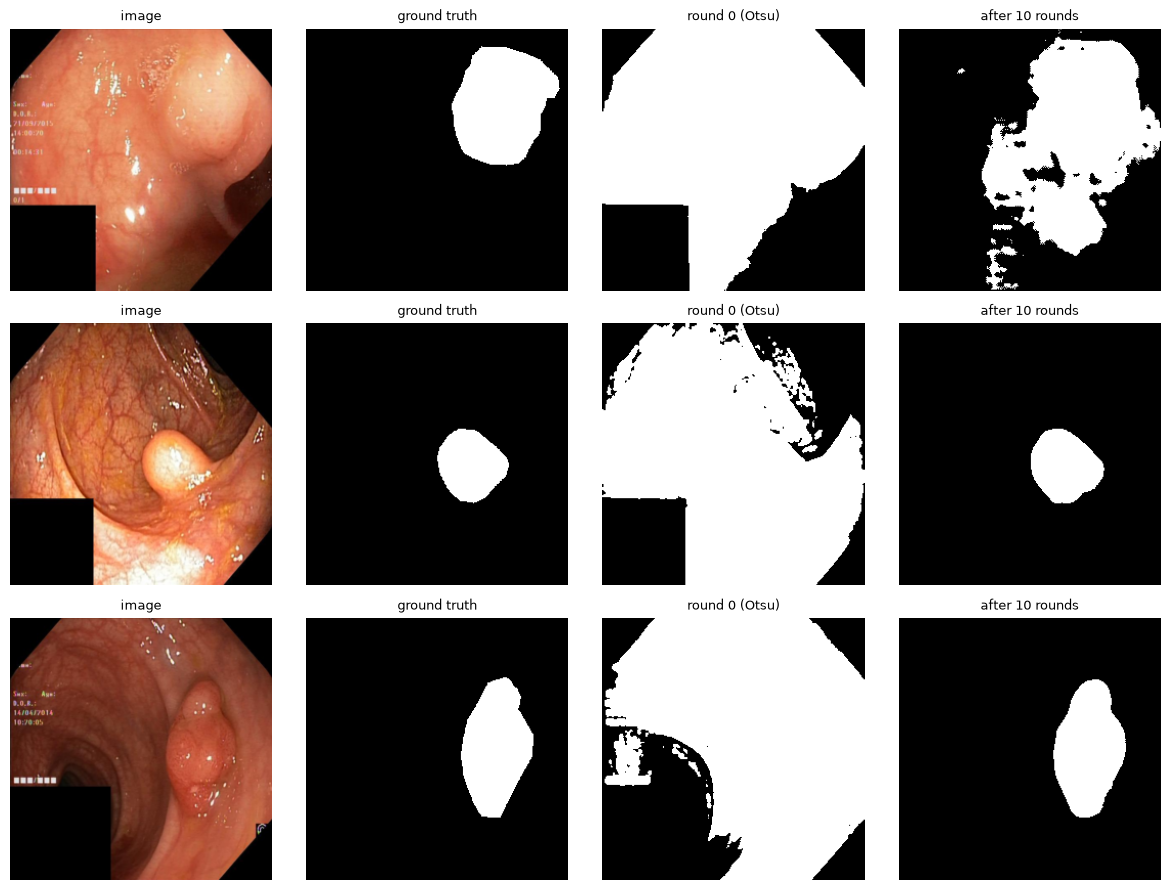

In [9]:
fig, ax = plt.subplots(3, 4, figsize=(12, 9))
for row, i in enumerate([3, 21, 64]):
    for a, img, t in zip(ax[row], [test.images[i], test.masks[i], otsu[i], mem_otsu.masks[i, 0].numpy()],
                         ["image", "ground truth", "round 0 (Otsu)", "after 10 rounds"]):
        a.imshow(img, cmap="gray"); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## 5. Ours vs the paper (Kvasir-SEG, 120 test images, 10 refinement rounds)

In [10]:
def last(path):
    return pd.read_csv(path).iloc[-1]
table = pd.DataFrame([
    ["FANet, paper (512×512)", 0.8803, 0.8153, 0.9058, 0.9005, 0.8872],
    ["Baseline without MixPool, paper (Table IX)", 0.8516, 0.7732, 0.8835, 0.8710, 0.8614],
    ["FANet, mine, paper's protocol (live, above)", *res_otsu.iloc[-1][["dice", "jaccard", "recall", "precision", "f2"]]],
    ["FANet, mine, empty start (live, above)", *res_zero.iloc[-1][["dice", "jaccard", "recall", "precision", "f2"]]],
    ["No feedback ablation (runs/kvasir_nofb)", *last("runs/kvasir_nofb/eval_test/results.csv")[["dice", "jaccard", "recall", "precision", "f2"]]],
    ["FANet, mine, 512×512 (runs/kvasir512-official)", *last("runs/kvasir512-official/eval_test/results.csv")[["dice", "jaccard", "recall", "precision", "f2"]]],
    ["First attempt, aligned memory aug (runs/kvasir)", *last("runs/kvasir/eval_test/results.csv")[["dice", "jaccard", "recall", "precision", "f2"]]],
], columns=["setting", "Dice", "mIoU", "Recall", "Precision", "F2"])
display(table.round(4))

,setting,Dice,mIoU,Recall,Precision,F2
0,"FANet, paper (512×512)",0.8803,0.8153,0.9058,0.9005,0.8872
1,"Baseline without MixPool, paper (Table IX)",0.8516,0.7732,0.8835,0.8710,0.8614
2,"FANet, mine, paper's protocol (live, above)",0.8422,0.7790,0.9341,0.8345,0.8684
3,"FANet, mine, empty start (live, above)",0.8999,0.8414,0.9001,0.9346,0.8977
4,No feedback ablation (runs/kvasir_nofb),0.8830,0.8171,0.8968,0.9149,0.8863
5,"FANet, mine, 512×512 (runs/kvasir512-official)",0.8305,0.7576,0.9166,0.8312,0.8596
6,"First attempt, aligned memory aug (runs/kvasir)",0.6835,0.5887,0.9578,0.6191,0.7749


**Reading.** Under the paper's protocol I get about 0.842 against 0.880. Resolution is not the cause (512×512: 0.831).
Likely causes: batch 8 vs 2, a different random test split, single runs. The **ablation** (feedback switched off) scores
0.883, so in this reproduction the feedback adds little, and the Otsu start hurts: the same weights reach 0.900 from an
empty start.

**Two findings from implementing it:**
1. The fmask head is thresholded with `> 0.5`, so it receives **no gradient**: about 13% of the parameters never train.
2. Moving the memory together with the augmentation ("aligned") made the model **copy its memory** (one-pass Dice 0.54
   from Otsu vs 0.85 from its own memory). The official misalignment works as a regulariser.

In [11]:
crit = FANet().to(device)
crit(torch.rand(2, 3, 64, 64, device=device), torch.ones(2, 1, 64, 64, device=device)).mean().backward()
dead = [(n, p.numel()) for n, p in crit.named_parameters() if p.grad is None]
print(f"parameters without gradient: {len(dead)} tensors, {sum(k for _, k in dead):,} values "
      f"({sum(k for _, k in dead) / count_parameters(crit):.1%}), all in fmask heads: {all('fmask' in n for n, _ in dead)}")
display(pd.read_csv("runs/kvasir/memory_probe.csv").round(3).head(10))

parameters without gradient: 48 tensors, 982,088 values (12.7%), all in fmask heads: True


,start,dice,precision,recall
0,Otsu,0.536,0.440,0.955
1,zeros,0.517,0.965,0.415
2,ones,0.383,0.267,0.993
3,ground truth,0.958,0.971,0.956
4,own memory,0.848,0.886,0.881


## 6. Detection view: boxes from the masks
Each connected blob of the mask becomes a bounding box (connected components written from scratch); predicted boxes
are matched to true boxes at IoU ≥ 0.5.

box metrics after 10 rounds (Otsu start): {'box_precision': 0.685, 'box_recall': 0.8, 'box_mean_iou': 0.881}


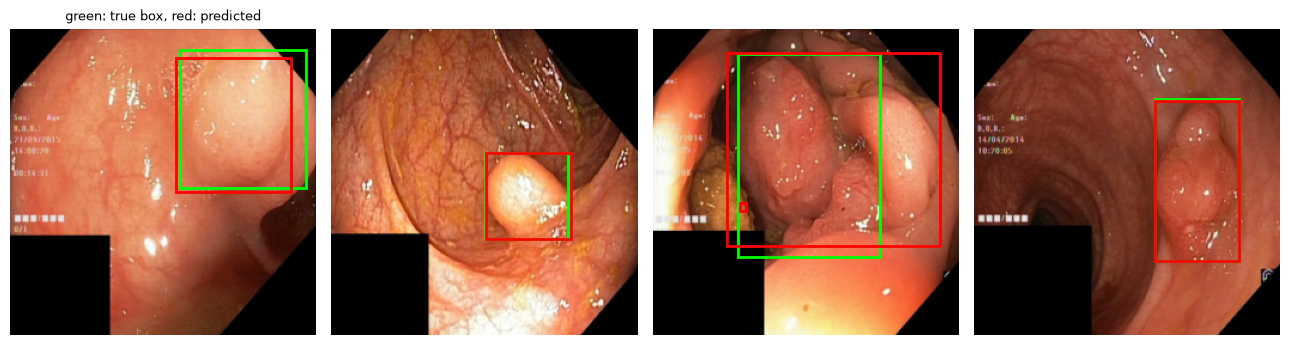

In [12]:
from matplotlib.patches import Rectangle
print("box metrics after 10 rounds (Otsu start):", res_otsu.iloc[-1][["box_precision", "box_recall", "box_mean_iou"]].round(3).to_dict())
fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for a, i in zip(ax, [3, 21, 40, 64]):
    a.imshow(test.images[i]); a.axis("off")
    for (x1, y1, x2, y2), c in [(b, "lime") for b in mask_to_boxes(test.masks[i])] + \
                               [(b, "red") for b in mask_to_boxes(mem_zero.masks[i, 0].numpy())]:
        a.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=c, lw=2))
ax[0].set_title("green: true box, red: predicted", fontsize=9); plt.tight_layout(); plt.show()

## 7. Own dataset: leaf disease spots, labelled in Roboflow
Colonoscopy data cannot be collected by a student, so the *task* is kept (irregular blobs on a textured surface) and the
*domain* changed to **disease spots on leaves**.

- **Source photos:** LDSD (Leaf Disease Segmentation Dataset, Kaggle, CC0; real photos from PlantDoc). 118 of them
  (20%) are the leaf **test set**, scored against LDSD's own masks.
- **My Roboflow dataset:** 30 other LDSD photos uploaded to Roboflow **without** masks; disease spots outlined by hand
  (Polygon / Smart Polygon), split 24 / 6, version v1 generated with flips, 90° rotations, ±15° rotation and ±15%
  brightness, 5× on the training photos only (126 images), exported as *Semantic Segmentation Masks* and converted
  with `python -m src.roboflow_to_masks`. Taking my own diseased-leaf photos was not possible, so the photos are public;
  the labels are mine. Public link: https://universe.roboflow.com/chaitanyadl/leaf-disease-seg-ib5ne

Roboflow dataset: train 120 images (with Roboflow's augmented copies), val 6


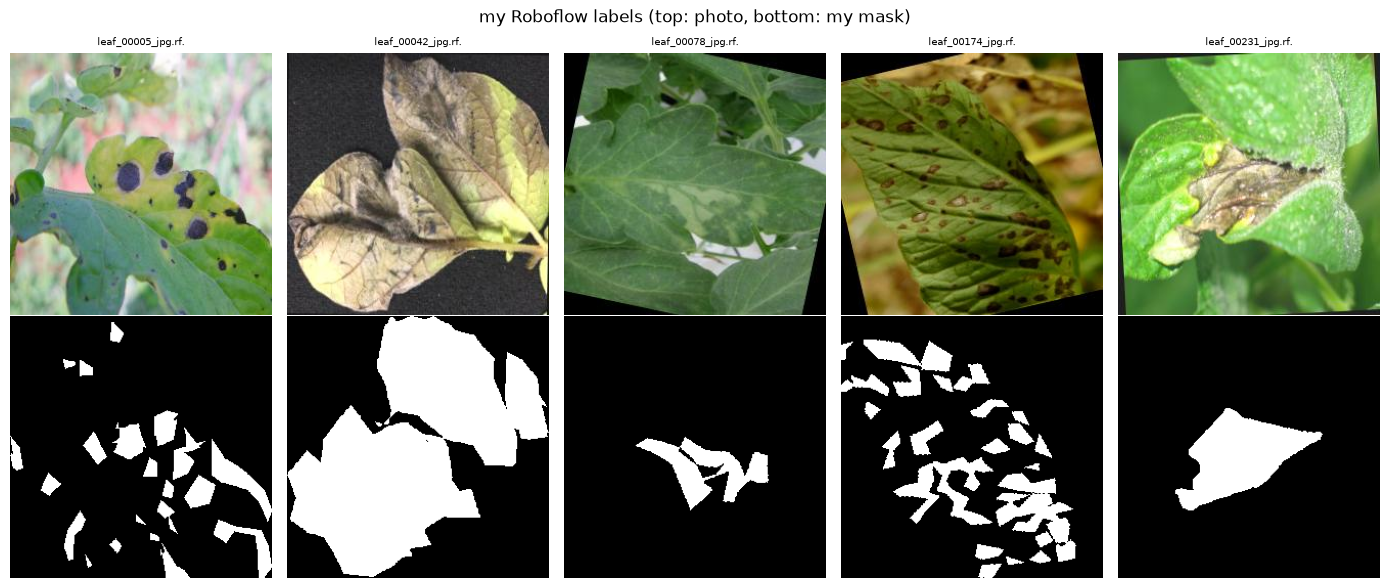

my hand labels vs LDSD's masks: Dice mean 0.730 over 30 photos


In [13]:
LDSD = "data/LDSD/data/data"
RF = "dataset/custom/roboflow_leaf"
if os.path.exists(f"{RF}/train.txt"):
    rf = SegmentationDataset(RF, "train", 256)
    print(f"Roboflow dataset: train {len(rf)} images (with Roboflow's augmented copies), "
          f"val {len(open(f'{RF}/val.txt').read().split()) if os.path.exists(f'{RF}/val.txt') else 0}")
    fig, ax = plt.subplots(2, 5, figsize=(14, 6))
    for k in range(5):
        i = k * max(len(rf) // 5, 1)
        ax[0, k].imshow(rf.images[i]); ax[1, k].imshow(rf.masks[i], cmap="gray")
        ax[0, k].set_title(rf.stems[i][:18], fontsize=7)
    for a in ax.ravel(): a.axis("off")
    plt.suptitle("my Roboflow labels (top: photo, bottom: my mask)"); plt.tight_layout(); plt.show()
    if os.path.exists(f"{RF}/agreement.csv"):
        ag = pd.read_csv(f"{RF}/agreement.csv")
        print(f"my hand labels vs LDSD's masks: Dice mean {ag.dice_vs_reference.mean():.3f} over {len(ag)} photos")
else:
    print("Roboflow export not converted yet: run python -m src.roboflow_to_masks (README §9)")

### Transfer results on the 118 LDSD test photos

In [14]:
def row(name, folder):
    out = [name]
    for sub in ("eval_test", "eval_test_zeros"):
        p = f"{folder}/{sub}/results.csv"
        out.append(pd.read_csv(p).dice.iloc[-1] if os.path.exists(p) else np.nan)
    return out
leaf = pd.DataFrame([
    row("polyp model, no fine-tuning", "runs/ldsd_zeroshot"),
    row("fine-tuned from polyp weights on 470 LDSD photos", "runs/ldsd_finetune"),
    row("trained from random weights on 470 LDSD photos", "runs/ldsd_scratch"),
    row("fine-tuned from polyp weights on my Roboflow photos (24 train)", "runs/roboflow_leaf_constlr_ldsd"),
    row("trained from random weights on my Roboflow photos (24 train)", "runs/roboflow_leaf_scratch_constlr_ldsd"),
], columns=["model", "Dice (Otsu start)", "Dice (empty start)"])
display(leaf.round(4))

,model,Dice (Otsu start),Dice (empty start)
0,"polyp model, no fine-tuning",0.0096,0.0042
1,fine-tuned from polyp weights on 470 LDSD photos,0.6700,0.6810
2,trained from random weights on 470 LDSD photos,0.6785,0.6669
3,fine-tuned from polyp weights on my Roboflow p...,0.5170,0.5203
4,trained from random weights on my Roboflow pho...,0.4667,0.4606


runs/roboflow_leaf_constlr/best.pt | LDSD test Dice after 3 rounds (empty start): 0.5269


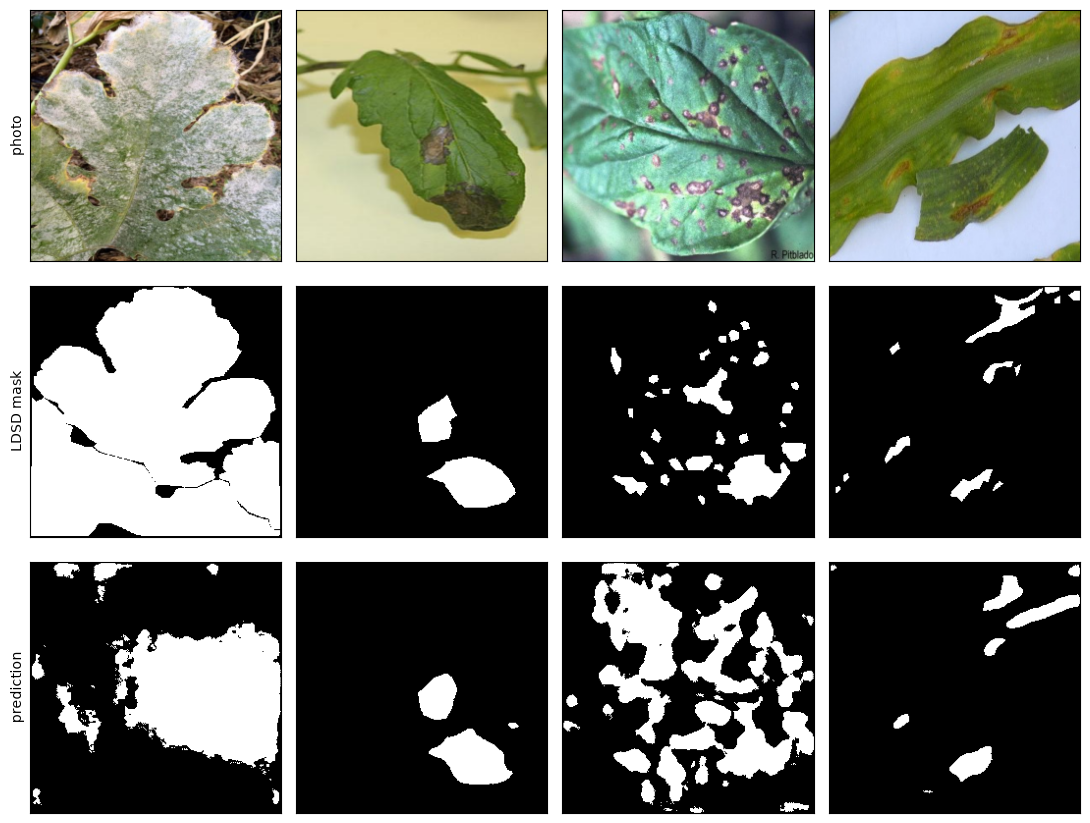

In [15]:
best_leaf = next((f for f in ["runs/roboflow_leaf_constlr/best.pt", "runs/ldsd_finetune/best.pt"] if os.path.exists(f)), None)
if best_leaf:
    leaf_test = SegmentationDataset(LDSD, "test", 256)
    lm = FANet().to(device); lm.load_state_dict(torch.load(best_leaf, map_location=device)["model"]); lm.eval()
    lres, lmem = refine(lm, leaf_test, "zeros", rounds=3)
    print(best_leaf, "| LDSD test Dice after 3 rounds (empty start):", round(lres.dice.iloc[-1], 4))
    fig, ax = plt.subplots(3, 4, figsize=(11, 8.5))
    for k, i in enumerate([2, 15, 33, 60]):
        ax[0, k].imshow(leaf_test.images[i]); ax[1, k].imshow(leaf_test.masks[i], cmap="gray")
        ax[2, k].imshow(lmem.masks[i, 0].numpy(), cmap="gray")
    for a, t in zip(ax[:, 0], ["photo", "LDSD mask", "prediction"]): a.set_ylabel(t)
    for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

## 7b. Lab rule: Roboflow detection dataset (tomato leaves, 4 classes)

The lab asks for a Roboflow dataset with **at least 200 annotated images and at least 4 classes** (detection or segmentation). FANet is binary, so this is a **separate Object Detection dataset**; FANet stays the main project.

| | |
|---|---|
| Photos | 220 tomato-leaf photos from PlantVillage (Hughes & Salathé, 2015), every 15th photo of each class folder |
| Classes | `bacterial_spot` (55), `early_blight` (55), `healthy` (55), `late_blight` (55) |
| Annotation | all 233 bounding boxes drawn by hand in Roboflow (whole leaf; on late blight, the blighted regions) |
| Version v1 | split 176 / 22 / 22; Auto-Orient, resize 640×640; flips, ±15° rotation, ±15% brightness, 3× on train → **572 images** |
| Export | YOLOv8 (one `.txt` per image: class, centre x, centre y, width, height, all 0–1) |
| Public | https://universe.roboflow.com/chaitanyadl/tomato-leaf-disease-det/dataset/1 |

One held-out photo per class from the export, with my box (figure made by `presentation/make_det_assets.py`):

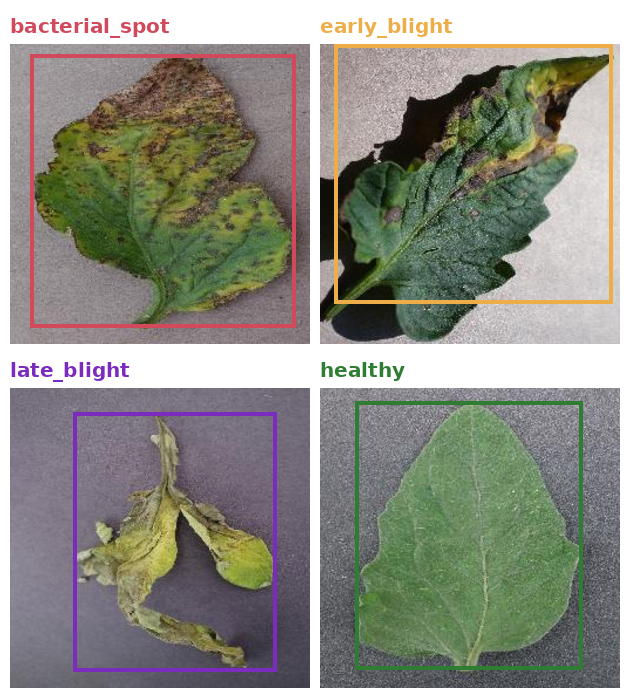

Training a detector (e.g. YOLO) on it is future work; the trained and tested model of this project is FANet (sections 2–7).

## 8. Conclusion
- FANet implemented from scratch and reproduced on Kvasir-SEG: Dice ≈ 0.842 under the paper's protocol (paper 0.880),
  0.900 with an empty starting mask.
- Critical findings: the feedback adds little in this reproduction (no-feedback ablation 0.883); 13% of the parameters
  (fmask heads) never train; the official memory misalignment prevents the model from copying its memory.
- Own dataset built in Roboflow (manual polygon labels + flips/rotations), and the polyp model transferred to leaf
  disease spots.

Full documentation: `docs/project_book.pdf` and `README.md`.